# 合成数据生成（第 1 部分）


使用大语言模型（LLM）生成合成数据，为一个常见问题提供了强有力的解决方案：如何获得高质量、多样化且符合隐私要求的数据。它可以用于许多场景，例如训练数据科学领域的机器学习模型（SVM、决策树、KNN）、在这些数据上微调另一个 GPT 模型、解决冷启动问题、用逼真的数据帮助构建有吸引力的演示/应用、场景测试等。

有几个关键因素可能促使你使用合成数据。
1. 人类数据可能受到隐私限制，和/或包含我们不希望被使用的可识别信息。
2. 合成数据可以比真实数据结构化得多，因此更易于处理。
3. 在数据稀缺或某些类别数据稀缺的领域，我们可能希望扩充数据。
4. 在处理不平衡或缺乏多样性的数据集时，我们可能希望创建数据来提升数据集的丰富度。

与传统的数据增强或手工创建数据的方法不同，使用 LLM 可以生成丰富、细致且与上下文相关的数据集，从而显著提升其对企业和开发者的价值。

我们将本教程分为 2 个部分。在本 cookbook 中，议程如下：
1. 使用结构化提示生成 CSV
2. 使用 Python 程序生成 CSV
3. 使用 Python 程序生成多表 CSV
4. 简单地创建文本数据
5. 处理不平衡或缺乏多样性的文本数据
而在第 2 部分中，我们将探讨如何通过提示策略获得更好的文本数据。

其中最后两项尤其适合用于创建合成数据来微调另一个 GPT 模型。例如，使用 `gpt-4o` 生成的高质量数据来微调更便宜、更快的 `gpt-3.5-turbo`，在提升性能的同时降低成本。


### 准备工作

In [ ]:
%pip install openai
%pip install pandas
%pip install scikit-learn
%pip install matplotlib

In [3]:
from openai import OpenAI
import os
import re
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import json
import matplotlib

client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "<your OpenAI API key if not set as env var>"))

### 1. 使用结构化提示生成 CSV
这里我们用最简单的方式创建数据。只需把握 3 个关键点就能快速生成数据：告诉它数据的格式（CSV）、schema，以及各列之间如何关联的有用信息（LLM 能够从列名中推断出这些关系，但提供一些帮助会提升效果）。

In [4]:
datagen_model = "gpt-4o-mini"
question = """
Create a CSV file with 10 rows of housing data.
Each row should include the following fields:
 - id (incrementing integer starting at 1)
 - house size (m^2)
 - house price
 - location
 - number of bedrooms

Make sure that the numbers make sense (i.e. more rooms is usually bigger size, more expensive locations increase price. more size is usually higher price etc. make sure all the numbers make sense). Also only respond with the CSV.
"""

response = client.chat.completions.create(
  model=datagen_model,
  messages=[
    {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
    {"role": "user", "content": question}
  ]
)
res = response.choices[0].message.content
print(res)

```csv
id,house_size_m2,house_price,location,number_of_bedrooms
1,50,150000,Suburban,2
2,75,250000,City Center,3
3,100,350000,Suburban,4
4,120,450000,Suburban,4
5,80,300000,City Center,3
6,90,400000,City Center,3
7,150,600000,Premium Area,5
8,200,750000,Premium Area,5
9,55,180000,Suburban,2
10,300,950000,Premium Area,6
```


### 2. 使用 Python 程序生成 CSV
直接生成数据的问题在于，受上下文限制，我们能生成的数据量有限。我们可以改为让 LLM 生成一个用于生成合成数据的 Python 程序。这样我们就能扩展到更多数据，同时还可以通过检查该 Python 程序了解数据是如何生成的。

这样我们就可以按需编辑这个 Python 程序，同时也有了一个不错的起点。


In [5]:
question = """
Create a Python program to generate 100 rows of housing data.
I want you to at the end of it output a pandas dataframe with 100 rows of data.
Each row should include the following fields:
 - id (incrementing integer starting at 1)
 - house size (m^2)
 - house price
 - location
 - number of bedrooms

Make sure that the numbers make sense (i.e. more rooms is usually bigger size, more expensive locations increase price. more size is usually higher price etc. make sure all the numbers make sense).
"""

response = client.chat.completions.create(
  model=datagen_model,
  messages=[
    {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
    {"role": "user", "content": question}
  ]
)
res = response.choices[0].message.content
print(res)

Certainly! Below is a Python program that generates synthetic housing data according to your specifications. We will create a pandas DataFrame with the defined fields and characteristics.

```python
import pandas as pd
import random

def generate_housing_data(num_rows):
    data = []
    
    locations = [
        ('City Center', 10000, 150),  # (location name, base price per m², base size)
        ('Suburban Area', 8000, 100),
        ('Country Side', 5000, 80),
        ('Coastal Region', 12000, 110),
        ('Urban Neighborhood', 9000, 130)
    ]
    
    for i in range(1, num_rows + 1):
        # Randomly pick a location
        location, base_price_per_m2, base_size = random.choice(locations)
        
        # Generate number of bedrooms (1 to 5)
        number_of_bedrooms = random.randint(1, 5)
        
        # Calculate house size based on the number of bedrooms
        house_size = base_size + (10 * number_of_bedrooms) + random.randint(-5, 15)  # Adding some noise
        
 

我们需要确保正确解析其输出，因为 Python 代码周围往往会有其他文本。我们也可以明确要求它说明对所生成数据做出的所有假设，不过在本例中它已经自动告诉了我们。

### 3. 使用 Python 程序生成多表 CSV
然而，对于更复杂的关系，我们需要确保指定更多的特征。

要创建多个相互关联的不同数据集（例如住房、位置、房屋类型），和之前一样，我们需要指定格式、schema 和有用信息。不过，现在要获得良好效果所需的有用信息更多了。具体情况因用例而异，但值得描述的内容包括：数据集之间如何关联、各数据集相对彼此的规模、确保外键和主键设置得当，并且最好使用先前生成的数据集来填充新的数据集，使实际数据值在必要时能够匹配。

In [6]:
question = """
Create a Python program to generate 3 different pandas dataframes.

1. Housing data
I want 100 rows. Each row should include the following fields:
 - id (incrementing integer starting at 1)
 - house size (m^2)
 - house price
 - location
 - number of bedrooms
 - house type
 + any relevant foreign keys

2. Location
Each row should include the following fields:
 - id (incrementing integer starting at 1)
 - country
 - city
 - population
 - area (m^2)
 + any relevant foreign keys

 3. House types
 - id (incrementing integer starting at 1)
 - house type
 - average house type price
 - number of houses
 + any relevant foreign keys

Make sure that the numbers make sense (i.e. more rooms is usually bigger size, more expensive locations increase price. more size is usually higher price etc. make sure all the numbers make sense).
Make sure that the dataframe generally follow common sense checks, e.g. the size of the dataframes make sense in comparison with one another.
Make sure the foreign keys match up and you can use previously generated dataframes when creating each consecutive dataframes.
You can use the previously generated dataframe to generate the next dataframe.
"""

response = client.chat.completions.create(
  model=datagen_model,
  messages=[
    {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
    {"role": "user", "content": question}
  ]
)
res = response.choices[0].message.content
print(res)

Certainly! Below is a Python program that generates the three specified pandas DataFrames for housing data, location data, and house types. Each DataFrame will include the necessary fields, and the foreign keys will ensure proper relationships among them.

```python
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(0)

# Function to generate location DataFrame
def generate_location_data(num_locations):
    locations = {
        "id": range(1, num_locations + 1),
        "country": np.random.choice(['USA', 'Canada', 'UK'], num_locations),
        "city": np.random.choice(['New York', 'Toronto', 'London', 'Vancouver', 'Manchester'], num_locations),
        "population": np.random.randint(50000, 1000000, num_locations),
        "area": np.random.randint(10000, 500000, num_locations)
    }
    return pd.DataFrame(locations)

# Function to generate house types DataFrame
def generate_house_type_data(num_house_types):
    house_types = {
        "id"

### 4. 简单地创建文本数据
这里我们初步了解如何创建文本数据。例如，这可以用来微调另一个 GPT 模型。在本例中，我们假设自己是一家零售商，正试图简化为所售商品撰写描述的流程。我们同样需要指定数据的格式，特别是在本例中，我们希望输出格式易于解析。

下面考虑的示例是创建供 GPT 模型微调使用的输入输出训练对。输入是产品名称及其所属类别，输出则是一段描述。

明确指定输出的结构，并下达不得偏离该结构的指令，有助于强制输出结构。你可以在循环中运行它并追加数据，以生成更多合成数据。同样，和之前一样，我们需要妥善解析数据，以免下游代码出错。

In [7]:
output_string = ""
for i in range(3):
  question = f"""
  I am creating input output training pairs to fine tune my gpt model. The usecase is a retailer generating a description for a product from a product catalogue. I want the input to be product name and category (to which the product belongs to) and output to be description.
  The format should be of the form:
  1.
  Input: product_name, category
  Output: description
  2.
  Input: product_name, category
  Output: description

  Do not add any extra characters around that formatting as it will make the output parsing break.
  Create as many training pairs as possible.
  """

  response = client.chat.completions.create(
    model=datagen_model,
    messages=[
      {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
      {"role": "user", "content": question}
    ]
  )
  res = response.choices[0].message.content
  output_string += res + "\n" + "\n"
print(output_string[:1000]) #displaying truncated response


1.
Input: Wireless Bluetooth Headphones, Electronics
Output: Immerse yourself in high-quality sound with these Wireless Bluetooth Headphones, featuring active noise cancellation and a comfortable over-ear design for extended listening sessions.

2.
Input: Organic Green Tea, Beverages
Output: Enjoy a refreshing cup of Organic Green Tea, sourced from the finest leaves, packed with antioxidants, and perfect for a healthy, invigorating boost anytime.

3.
Input: Stainless Steel Kitchen Knife, Kitchenware
Output: Cut with precision and ease using this Stainless Steel Kitchen Knife, designed with an ergonomic handle and a sharp blade for all your culinary tasks.

4.
Input: Hiking Backpack, Outdoor Gear
Output: Explore the great outdoors with this durable Hiking Backpack, featuring multiple compartments for optimal organization and a breathable design for ultimate comfort on long treks.

5.
Input: Air Fryer, Kitchen Appliances
Output: Cook your favorite meals with less oil using this Air Fryer

注意：上面的输出已被截断。现在我们可以按如下方式解析它，得到产品、类别及其描述的列表。例如，我们来看看它生成了哪些产品。

In [8]:
#regex to parse data
pattern = re.compile(r'Input:\s*(.+?),\s*(.+?)\nOutput:\s*(.+?)(?=\n\n|\Z)', re.DOTALL)
matches = pattern.findall(output_string)
products = []
categories = []
descriptions = []

for match in matches:
    product, category, description = match
    products.append(product.strip())
    categories.append(category.strip())
    descriptions.append(description.strip())
products

['Wireless Bluetooth Headphones',
 'Organic Green Tea',
 'Stainless Steel Kitchen Knife',
 'Hiking Backpack',
 'Air Fryer',
 "Kids' Educational Tablet",
 'Bluetooth Speaker',
 'Yoga Mat',
 'Memory Foam Mattress',
 'Smartwatch',
 'Leather Wallet',
 'Portable Phone Charger',
 'Non-Stick Cookware Set',
 'Pet Dog Bed',
 'Fitness Tracker',
 'Wireless Earbuds',
 'Organic Green Tea',
 'Reusable Water Bottle',
 'Yoga Mat',
 'Leather Wallet',
 'Air Fryer',
 'Gaming Mouse',
 'Crochet Kit',
 'Hiking Boots',
 'Scented Candles',
 'Bluetooth Speaker',
 'Stainless Steel Cookware Set',
 'Fitness Tracker',
 'Decorative Throw Pillows',
 'Eco-Friendly Cleaning Supplies',
 'Wireless Noise Cancelling Headphones',
 'Organic Green Tea',
 'Adjustable Yoga Mat',
 'Bluetooth Smart Scale',
 'Stainless Steel Water Bottle',
 'Soft Cotton Bedding Set',
 'Multi-Functional Kitchen Blender',
 'Eco-Friendly Reusable Bags',
 'Portable Phone Charger',
 'Classic Leather Wallet',
 'Suede Chelsea Boots',
 'Non-Stick Cookwar


### 5. 处理不平衡或缺乏多样性的文本数据
生成高质量合成数据最重要的几个方面是准确性（数据是否合理）、一致性（同一输入对应的两个独立数据点是否大致相同）和多样性（确保数据分布尽可能匹配生产环境中存在的分布）。


为了提升数据的多样性，我们首先对数据进行聚类。这能告诉我们哪些簇代表性不足（数据集不平衡），或者哪些数据完全没有覆盖到（扩展数据分布）。然后，我们要么提出新的簇（通过 GPT 的自我反思类调用），要么让下一轮合成数据生成调用明确针对代表性不足的簇。

然后，我们可以递归地运行这个生成与簇分析的循环，从而自动生成多样化的合成数据。

出于演示目的，我们明确提示 LLM 生成关于 4 个不同主题领域的信息：车辆、服装、洗漱用品、食品。然后我们会对数据进行聚类，看看是否能找出这 4 个主题领域。

In [19]:
output_string = ""
for i in range(3):
  question = f"""
  I am creating input output training pairs to fine tune my gpt model. I want the input to be product name and category and output to be description. the category should be things like: mobile phones, shoes, headphones, laptop, electronic toothbrush, etc. and also more importantly the categories should come under 4 main topics: vehicle, clothing, toiletries, food)
  After the number of each example also state the topic area. The format should be of the form:
  1. topic_area
  Input: product_name, category
  Output: description

  Do not add any extra characters around that formatting as it will make the output parsing break.

  Here are some helpful examples so you get the style of output correct.

  1) clothing
  Input: "Shoe Name, Shoes"
  Output: "Experience unparalleled comfort. These shoes feature a blend of modern style and the traditional superior cushioning, perfect for those always on the move."
  """

  response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
      {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
      {"role": "user", "content": question}
    ]
  )
  res = response.choices[0].message.content
  output_string += res + "\n" + "\n"
print(output_string[:1000]) #displaying truncated response

1. vehicle  
Input: "Tesla Model 3, Electric Car"  
Output: "The Tesla Model 3 is a revolutionary electric car with impressive range and cutting-edge technology, designed to provide an exhilarating driving experience while minimizing environmental impact."

2. clothing  
Input: "Nike Air Max, Shoes"  
Output: "Elevate your sneaker game with Nike Air Max. Combining iconic style with superior comfort and support, these shoes are perfect for both workouts and casual outings."

3. toiletries  
Input: "Oral-B Pro 1000, Electronic Toothbrush"  
Output: "Achieve a superior clean with the Oral-B Pro 1000. This electronic toothbrush features 3D cleaning action that pulsates and oscillates to remove more plaque than a regular manual toothbrush."

4. food  
Input: "Chobani Greek Yogurt, Yogurt"  
Output: "Indulge in a nutritious snack with Chobani Greek Yogurt. Packed with protein and delicious flavors, it’s the perfect choice for a healthy breakfast or a satisfying treat anytime."

5. vehicle  


注意：上面的输出已被截断。在上面的示例中，我们会在每个示例的回答中明确包含主题领域，因为这有助于约束后续输出，并且通常能带来更好的效果。我们还可以给它一个输出应有样子的实际示例，这样它既能正确把握输出风格，也有助于强制输出结构。

In [22]:
pattern = re.compile(r'(\d+)\.\s*(\w+)\s*Input:\s*"(.+?),\s*(.+?)"\s*Output:\s*"(.*?)"', re.DOTALL)
matches = pattern.findall(output_string)

topics = []
products = []
categories = []
descriptions = []

for match in matches:
    number, topic, product, category, description = match
    topics.append(topic)
    products.append(product)
    categories.append(category)
    descriptions.append(description)


In [23]:
products

['Tesla Model 3',
 'Nike Air Max',
 'Oral-B Pro 1000',
 'Chobani Greek Yogurt',
 'Ford F-150',
 "Levi's 511",
 'Philips Sonicare',
 'Quaker Oatmeal',
 'Toyota Camry',
 'Adidas Ultraboost',
 'Toyota Camry',
 'Nike Air Max',
 'Colgate Electric Toothbrush',
 'Blue Diamond Almonds',
 'Harley Davidson Fat Boy',
 'Adidas UltraBoost',
 "Dove Men's Body Wash",
 'Quaker Oats',
 'Ford F-150',
 "Levi's 501 Jeans",
 'Tesla Model 3',
 'Nike Air Max',
 'Oral-B Pro 1000',
 'Organic Almond Butter',
 'Yamaha YZF-R3',
 'Adidas Ultraboost',
 'Philips Sonicare',
 'Organic Quinoa']

现在我们将对数据进行聚类以便分析。我们将使用 K-means 聚类来划分数据。K-means 需要设置的一个重要参数是 K，即簇的数量。

我们知道应该有 4 个簇（4 个主题），因为我们在提示中指定了：车辆、电子产品、服装、食品。然而一般来说，对于我们的数据，我们并不知道存在多少个簇。因此，我们将使用肘部法（elbow method）来找出最佳簇数。

在肘部法中，我们遍历一系列不同的 K 值，每次都记录惯性（inertia）。惯性衡量的是簇中每个点到该簇质心的距离平方和，从而告诉我们每个簇的分离程度和密集程度。如果我们绘制 K 与惯性的关系图，就能看到惯性如何下降，在惯性下降变得最缓慢的地方（通常形成一个肘部形状），我们就可以确定最佳簇数。你可以在[这里](https://en.wikipedia.org/wiki/Elbow_method_(clustering))更深入地了解肘部法。

首先，为了便于分析，我们将数据存储到 pandas dataframe 中



In [24]:
data = {
    'Product': products,
    'Category': categories,
    'Description': descriptions
}

df = pd.DataFrame(data)

接下来对数据进行嵌入，因为我们要聚类的正是嵌入：相似的数据在向量空间中应该彼此接近。

In [25]:
def get_embedding(text, model="text-embedding-3-small"):
    text = text.replace("\n", " ")

    response = client.embeddings.create(input=[text], model=model)

    return response.data[0].embedding

embedding_model = "text-embedding-3-small"
df["embedding"] = df.Category.apply(lambda x: get_embedding(x, model=embedding_model))

# Ensure there are embeddings to concatenate
if len(df.embedding.values) > 0:
    matrix = np.vstack(df.embedding.values)
else:
    matrix = np.array([])  # Handle the case where there are no embeddings


In [26]:
df

,Product,Category,Description,embedding
0,Tesla Model 3,Electric Car,The Tesla Model 3 is a revolutionary electric ...,"[0.003255360759794712, -0.039260633289813995, ..."
1,Nike Air Max,Shoes,Elevate your sneaker game with Nike Air Max. C...,"[0.03943369910120964, 0.022045187652111053, -0..."
2,Oral-B Pro 1000,Electronic Toothbrush,Achieve a superior clean with the Oral-B Pro 1...,"[-0.003470012918114662, -0.01911414973437786, ..."
3,Chobani Greek Yogurt,Yogurt,Indulge in a nutritious snack with Chobani Gre...,"[0.0208318829536438, -0.02645781636238098, -0...."
4,Ford F-150,Pickup Truck,"The Ford F-150 is the ultimate pickup truck, d...","[0.007467855699360371, -0.05288049206137657, -..."
5,Levi's 511,Jeans,Step out in style with Levi's 511 jeans. Featu...,"[0.0037206460256129503, 0.022772302851080894, ..."
6,Philips Sonicare,Electric Toothbrush,Discover a new level of oral care with the Phi...,"[-0.00724813062697649, -0.011600878089666367, ..."
7,Quaker Oatmeal,Breakfast Cereal,Start your day right with Quaker Oatmeal. This...,"[-0.006529285106807947, 0.007865572348237038, ..."
8,Toyota Camry,Sedan,The Toyota Camry stands out in the sedan categ...,"[-0.02088991366326809, -0.006191295105963945, ..."
9,Adidas Ultraboost,Running Shoes,Run like never before in the Adidas Ultraboost...,"[0.02679188922047615, 0.014639599248766899, 8...."


现在执行肘部法。 

In [27]:
# Determine the optimal number of clusters using the elbow method
inertias = []
range_of_clusters = range(1, 13)  # Adjust the range as necessary

for n_clusters in range_of_clusters:
    kmeans = KMeans(n_clusters=n_clusters, init="k-means++", random_state=42, n_init=10)
    kmeans.fit(matrix)
    inertias.append(kmeans.inertia_)


这会为我们输出一张图表，我们需要通过目测判断最佳簇点在哪里。从下图可以看出，惯性是逐渐下降的，而不是出现一个明显的肘部，但下降最陡的点似乎出现在 3、4 或 5 个簇附近，这与我们根据提示所做的预期相符。 

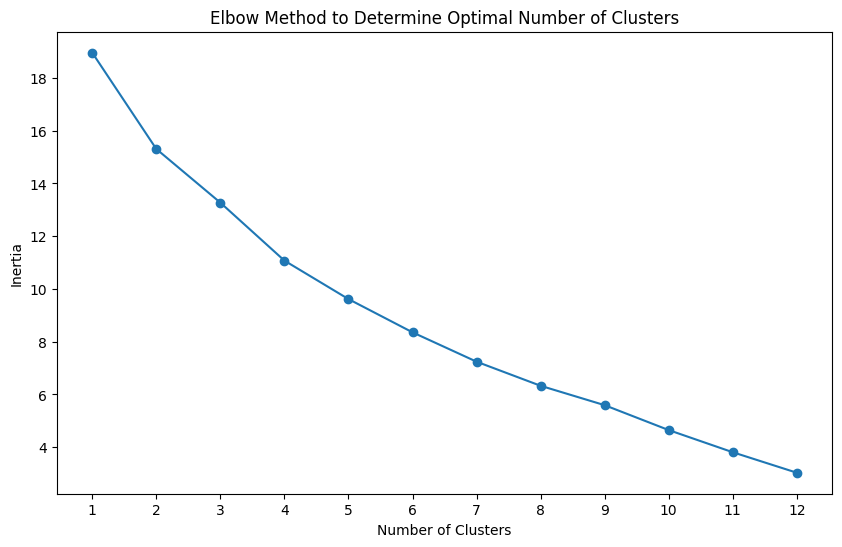

In [28]:
# Plotting the elbow plot
plt.figure(figsize=(10, 6))
plt.plot(range_of_clusters, inertias, '-o')
plt.title('Elbow Method to Determine Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.xticks(range_of_clusters)
plt.show()

![肘部图](../images/elbow_chart.png)

出于演示目的，我们将选择 5 作为最佳簇数，以说明只要大致正确，具体选在哪里并不重要。对数据进行分类的正确方式有很多种。我们还会记录每个数据点所属的簇。

In [29]:
n_clusters = 5

kmeans = KMeans(n_clusters=n_clusters, init="k-means++", random_state=42)
kmeans.fit(matrix)
labels = kmeans.labels_
df["Cluster"] = labels

现在我们来分析聚类数据。我们要解决两个不同的问题：1. 数据不平衡，2. 扩展数据分布。

首先，针对数据不平衡问题，我们统计每个簇中的示例数量。然后从每个簇中随机选取几个示例，询问 LLM 它们对应哪些主题。 

In [30]:
cluster_counts = df["Cluster"].value_counts().sort_index()
print(cluster_counts)

Cluster
0    5
1    7
2    8
3    6
4    2
Name: count, dtype: int64


可以看到这里找到的主题：
Eco-friendly Transportation、Luxury and Leisure Items、Personal Care Products、Electronic Toothbrushes 以及 Clothing and Apparel
与我们最初提示中的主题：
车辆、服装、洗漱用品、食品
匹配得还算不错，但并不完全一致。

由于我们选择了 5 个簇，它把洗漱用品拆分成了护肤和个人护理，这对下游影响不大。

In [33]:
df

,Product,Category,Description,embedding,Cluster
0,Tesla Model 3,Electric Car,The Tesla Model 3 is a revolutionary electric ...,"[0.003255360759794712, -0.039260633289813995, ...",1
1,Nike Air Max,Shoes,Elevate your sneaker game with Nike Air Max. C...,"[0.03943369910120964, 0.022045187652111053, -0...",2
2,Oral-B Pro 1000,Electronic Toothbrush,Achieve a superior clean with the Oral-B Pro 1...,"[-0.003470012918114662, -0.01911414973437786, ...",1
3,Chobani Greek Yogurt,Yogurt,Indulge in a nutritious snack with Chobani Gre...,"[0.0208318829536438, -0.02645781636238098, -0....",3
4,Ford F-150,Pickup Truck,"The Ford F-150 is the ultimate pickup truck, d...","[0.007467855699360371, -0.05288049206137657, -...",0
5,Levi's 511,Jeans,Step out in style with Levi's 511 jeans. Featu...,"[0.0037206460256129503, 0.022772302851080894, ...",2
6,Philips Sonicare,Electric Toothbrush,Discover a new level of oral care with the Phi...,"[-0.00724813062697649, -0.011600878089666367, ...",1
7,Quaker Oatmeal,Breakfast Cereal,Start your day right with Quaker Oatmeal. This...,"[-0.006529285106807947, 0.007865572348237038, ...",3
8,Toyota Camry,Sedan,The Toyota Camry stands out in the sedan categ...,"[-0.02088991366326809, -0.006191295105963945, ...",0
9,Adidas Ultraboost,Running Shoes,Run like never before in the Adidas Ultraboost...,"[0.02679188922047615, 0.014639599248766899, 8....",2


In [36]:
selected_examples = df.groupby('Cluster').apply(lambda x: x.sample(3, replace=True)).reset_index(drop=True)

# Format the selected examples
formatted_examples = "\n".join(
    f'Input: "{row["Product"]}, {row["Category"]}"\nOutput: "{row["Description"]}"\nCluster: "{row["Cluster"]}"'
    for _, row in selected_examples.iterrows()
)

topic_prompt = f"""
    I previously generated some examples of input output trainings pairs and then I clustered them based on category. From each cluster I picked 3 example data point which you can find below.
    I want you identify the broad topic areas these clusters belong to.
    Previous examples:
    {formatted_examples}


    Your output should be strictly of the format:
    Cluster: number, topic: topic
    Cluster: number, topic: topic
    Cluster: number, topic: topic

    Do not add any extra characters around that formatting as it will make the output parsing break.
    """

response = client.chat.completions.create(
  model=datagen_model,
  messages=[
    {"role": "system", "content": "You are a helpful assistant designed analyze clustered data"},
    {"role": "user", "content": topic_prompt}
  ]
)
res = response.choices[0].message.content

pattern = r"Cluster: (\d+), topic: ([^\n]+)"
matches = re.findall(pattern, res)
clusters = [{"cluster": int(cluster), "topic": topic} for cluster, topic in matches]
json_output = json.dumps(clusters, indent=2)
print(json_output)

[
  {
    "cluster": 0,
    "topic": "Automotive  "
  },
  {
    "cluster": 1,
    "topic": "Personal Care  "
  },
  {
    "cluster": 2,
    "topic": "Footwear  "
  },
  {
    "cluster": 3,
    "topic": "Food  "
  },
  {
    "cluster": 4,
    "topic": "Automotive  "
  }
]


现在我们有了簇及其数量，因此可以提示 LLM 在我们想要的主题中生成更多示例。不过在本例中我们不会进一步展开，因为这些簇划分得已经很均衡；你只需按照上面的流程提示模型生成数据，同时传入代表性不足的主题即可。

接下来，我们将尝试提升数据分布的多样性。

首先，我们以类似的方式开始：从每个簇中随机找出几个示例，询问 LLM 它们对应哪些主题。此外，在同一次 LLM 调用中，我们还会让它生成更多主题，以提升数据的多样性。我们在一次调用中完成这些，以节省时间和成本。

In [37]:
selected_examples = df.groupby('Cluster').apply(lambda x: x.sample(3, replace=True)).reset_index(drop=True)

# Format the selected examples
formatted_examples = "\n".join(
    f'Input: "{row["Product"]}, {row["Category"]}"\nOutput: "{row["Description"]}"\nCluster: "{row["Cluster"]}"'
    for _, row in selected_examples.iterrows()
)

topic_prompt = f"""
    I previously generated some examples of input output trainings pairs and then I clustered them based on category. From each cluster I picked 3 example data point which you can find below.
    I want to promote diversity in my examples across categories so follow the procedure below:
    1. You must identify the broad topic areas these clusters belong to.
    2. You should generate further topic areas which don't exist so I can generate data within these topics to improve diversity.


    Previous examples:
    {formatted_examples}


    Your output should be strictly of the format:

    1. Cluster topic mapping
    Cluster: number, topic: topic
    Cluster: number, topic: topic
    Cluster: number, topic: topic

    2. New topics
    1. topic
    2. topic
    3. topic
    4. topic

    Do not add any extra characters around that formatting as it will make the output parsing break. It is very important you stick to that output format
    """

response = client.chat.completions.create(
  model=datagen_model,
  messages=[
    {"role": "system", "content": "You are a helpful assistant designed to analyze clustered data"},
    {"role": "user", "content": topic_prompt}
  ]
)
res = response.choices[0].message.content
print(res)


1. Cluster topic mapping
Cluster: 0, topic: Automotive
Cluster: 1, topic: Personal Care
Cluster: 2, topic: Footwear
Cluster: 3, topic: Food
Cluster: 4, topic: Electric Vehicles

2. New topics
1. topic: Home Appliances
2. topic: Outdoor Equipment
3. topic: Smart Home Technology
4. topic: Fitness Equipment


可以看到，我们在这里再次明确提示了它应遵循的输出结构。我还告诉了它生成主题的目的（提升多样性），让模型掌握完整的上下文。

然后，我们将数据解析为一个簇映射 json 列表和一个主题列表

In [38]:
parts = res.split("\n\n")
cluster_mapping_part = parts[0]
new_topics_part = parts[1]

# Parse cluster topic mapping
cluster_topic_mapping_lines = cluster_mapping_part.split("\n")[1:]  # Skip the first two lines
cluster_topic_mapping = [{"cluster": int(line.split(",")[0].split(":")[1].strip()), "topic": line.split(":")[2].strip()} for line in cluster_topic_mapping_lines]

# Parse new topics
new_topics_lines = new_topics_part.split("\n")[1:]  # Skip the first line
new_topics = [line.split(". ")[1] for line in new_topics_lines]

cluster_topic_mapping, new_topics

([{'cluster': 0, 'topic': 'Automotive'},
  {'cluster': 1, 'topic': 'Personal Care'},
  {'cluster': 2, 'topic': 'Footwear'},
  {'cluster': 3, 'topic': 'Food'},
  {'cluster': 4, 'topic': 'Electric Vehicles'}],
 ['topic: Home Appliances',
  'topic: Outdoor Equipment',
  'topic: Smart Home Technology',
  'topic: Fitness Equipment'])

最后，我们可以利用这些信息进一步提示模型继续生成合成数据。具体做法是将 json 列表中的所有主题传入下面的提示。

In [39]:
output_string = ""
for i in range(3):
  question = f"""
  I am creating input output training pairs to fine tune my gpt model. I want the input to be product name and category and output to be description. the category should be things like: mobile phones, shoes, headphones, laptop, electronic toothbrush, etc. and also more importantly the categories should come under some main topics: {[entry['topic'] for entry in cluster_topic_mapping]})
  After the number of each example also state the topic area. The format should be of the form:
  1. topic_area
  Input: product_name, category
  Output: description

  Do not add any extra characters around that formatting as it will make the output parsing break.

  Here are some helpful examples so you get the style of output correct.

  1) clothing
  Input: "Shoe Name, Shoes"
  Output: "Experience unparalleled comfort. These shoes feature a blend of modern style and the traditional superior cushioning, perfect for those always on the move."
  """

  response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
      {"role": "system", "content": "You are a helpful assistant designed to generate synthetic data."},
      {"role": "user", "content": question}
    ]
  )
  res = response.choices[0].message.content
  output_string += res + "\n" + "\n"
print(output_string)

1. Automotive  
Input: "Tesla Model S, Electric Vehicles"  
Output: "The Tesla Model S delivers exhilarating performance with advanced electric technology, offering a sleek design, impressive range, and an industry-leading infotainment system."

2. Personal Care  
Input: "Oral-B Pro 1000, Electronic Toothbrush"  
Output: "The Oral-B Pro 1000 features a 3D cleaning action that oscillates, rotates, and pulsates to remove plaque, ensuring a deeper clean for healthier gums."

3. Footwear  
Input: "Nike Air Max 270, Shoes"  
Output: "Step into comfort and style with Nike Air Max 270, designed with a large Max Air unit for superior cushioning and a breathable upper for a snug fit."

4. Electronics  
Input: "Apple iPhone 12, Mobile Phones"  
Output: "The Apple iPhone 12 combines powerful performance with stunning design, equipped with A14 Bionic chip and advanced camera systems for capturing every moment in stunning detail."

5. Food  
Input: "Nature Valley Granola Bars, Snacks"  
Output: "Na

你可以在循环中运行它，将结果追加到之前的数据中。通过这种方式，你可以不断生成更多文本合成数据来训练另一个 GPT 模型，同时确保照顾到不平衡的数据集并生成多样化的数据。

你现在已经完成了合成数据生成教程的第 1 部分，其中我们介绍了：
*   使用结构化提示生成 CSV
*   使用 Python 程序生成 CSV
*   使用 Python 程序生成多表 CSV
*   简单地创建文本数据
*   处理不平衡或缺乏多样性的文本数据

在第 2 部分中，你将了解如何更好地提示 LLM，以增强文本合成数据的生成。